In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

sales = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "Laptops":    [40, 42, 45, 38, 36, 35, 41, 48, 52, 85, 95, 60],
    "Phones":     [55, 54, 58, 60, 57, 59, 62, 64, 66, 90, 98, 72],
    "Headphones": [20, 22, 21, 25, 24, 26, 25, 27, 30, 45, 52, 40],
})

sales


,Month,Laptops,Phones,Headphones
0,Jan,40,55,20
1,Feb,42,54,22
2,Mar,45,58,21
3,Apr,38,60,25
4,May,36,57,24
5,Jun,35,59,26
6,Jul,41,62,25
7,Aug,48,64,27
8,Sep,52,66,30
9,Oct,85,90,45


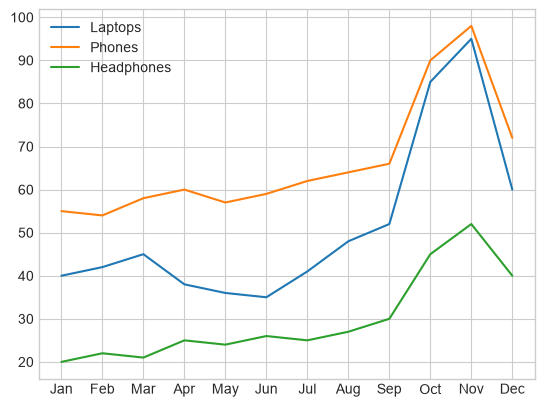

In [11]:
#Task 1
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

sales = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "Laptops": [40, 42, 45, 38, 36, 35, 41, 48, 52, 85, 95, 60],
    "Phones": [55, 54, 58, 60, 57, 59, 62, 64, 66, 90, 98, 72],
    "Headphones": [20, 22, 21, 25, 24, 26, 25, 27, 30, 45, 52, 40]
})

plt.figure()

plt.plot(sales["Month"], sales["Laptops"], label="Laptops")
plt.plot(sales["Month"], sales["Phones"], label="Phones")
plt.plot(sales["Month"], sales["Headphones"], label="Headphones")

plt.legend()
plt.savefig("before.png")
plt.show()

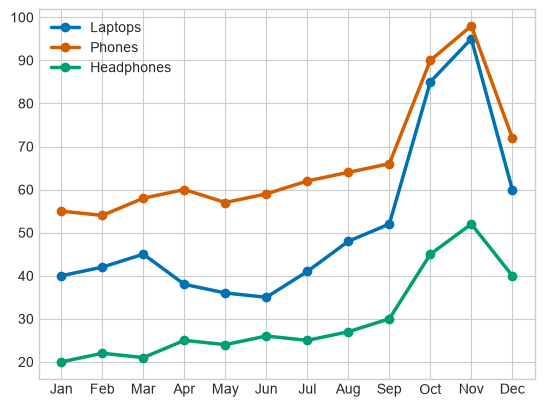

In [12]:
#Task 2
plt.style.use("seaborn-v0_8-whitegrid")

colors = {
    "Laptops": "#0072B2",
    "Phones": "#D55E00",
    "Headphones": "#009E73"
}

fig, ax = plt.subplots()

for product, color in colors.items():
    ax.plot(
        sales["Month"],
        sales[product],
        label=product,
        color=color,
        linewidth=2.5,
        marker="o"
    )

ax.legend()
plt.show()

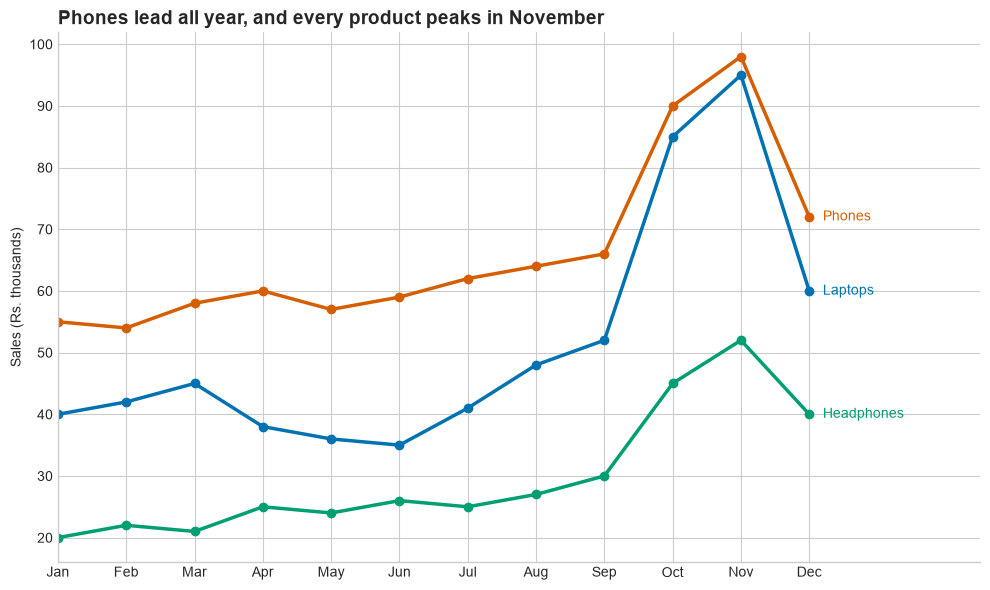

In [13]:
#Task 3
fig, ax = plt.subplots(figsize=(10, 6))

for product, color in colors.items():
    ax.plot(
        sales["Month"],
        sales[product],
        color=color,
        linewidth=2.5,
        marker="o"
    )

    last_value = sales[product].iloc[-1]

    ax.text(
        11.2,
        last_value,
        product,
        color=color,
        va="center"
    )

ax.set_title(
    "Phones lead all year, and every product peaks in November",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

ax.set_ylabel("Sales (Rs. thousands)")

ax.set_xticks(range(12))
ax.set_xticklabels(sales["Month"])

ax.set_xlim(0, 13.5)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

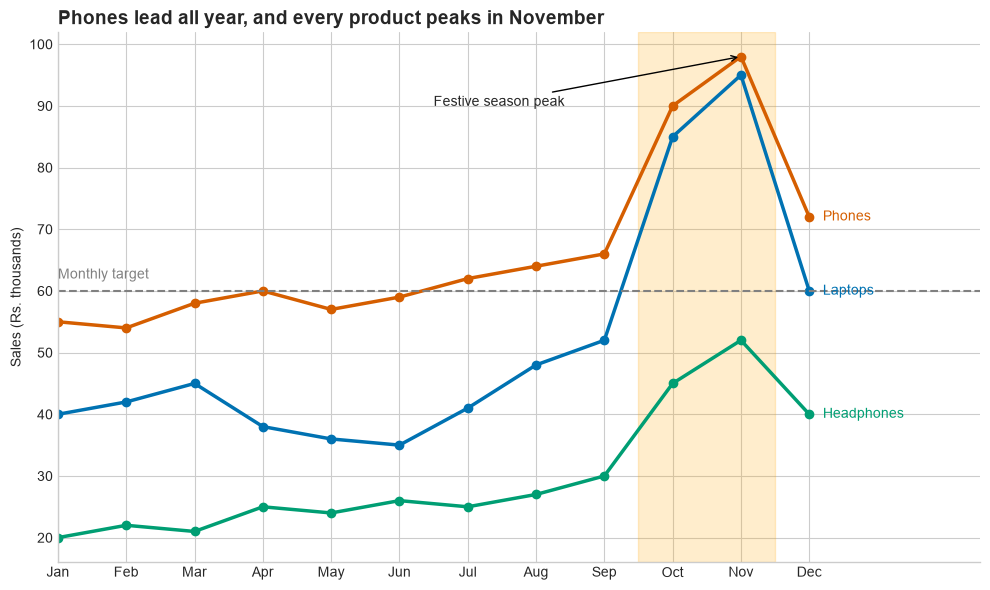

In [14]:
#Task 4
fig, ax = plt.subplots(figsize=(10, 6))

for product, color in colors.items():
    ax.plot(
        sales["Month"],
        sales[product],
        color=color,
        linewidth=2.5,
        marker="o"
    )

    last_value = sales[product].iloc[-1]

    ax.text(
        11.2,
        last_value,
        product,
        color=color,
        va="center"
    )

ax.set_title(
    "Phones lead all year, and every product peaks in November",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

ax.set_ylabel("Sales (Rs. thousands)")

ax.set_xticks(range(12))
ax.set_xticklabels(sales["Month"])
ax.set_xlim(0, 13.5)

ax.axvspan(8.5, 10.5, color="orange", alpha=0.2)

ax.annotate(
    "Festive season peak",
    xy=(10, 98),
    xytext=(5.5, 90),
    arrowprops=dict(arrowstyle="->")
)

# Add monthly target line
ax.axhline(60, linestyle="--", color="grey")
ax.text(0, 62, "Monthly target", color="grey")

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("after.png", dpi=150, bbox_inches="tight")
plt.show()

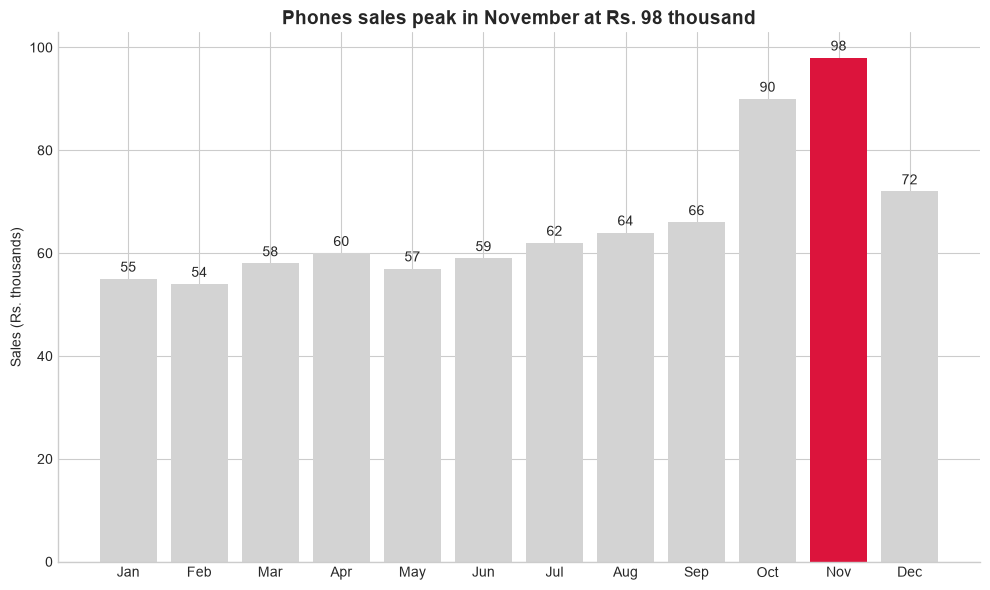

In [15]:
#Task 5
fig, ax = plt.subplots(figsize=(10, 6))

highest_month = sales["Phones"].idxmax()

bar_colors = [
    "crimson" if i == highest_month else "lightgrey"
    for i in range(len(sales))
]

bars = ax.bar(
    sales["Month"],
    sales["Phones"],
    color=bar_colors
)

ax.bar_label(bars, padding=3)

ax.set_title(
    "Phones sales peak in November at Rs. 98 thousand",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Sales (Rs. thousands)")

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [16]:
#Task 6

long = sales.melt(
    id_vars="Month",
    var_name="Product",
    value_name="Sales"
)


fig = px.line(
    long,
    x="Month",
    y="Sales",
    color="Product",
    markers=True,
    color_discrete_map=colors,
    template="simple_white",
    title="Phones lead all year, and every product peaks in November"
)


fig.update_traces(
    line_width=3,
    hovertemplate="%{x}: Rs. %{y}k"
)


fig.update_layout(
    yaxis_title="Sales (Rs. thousands)"
)


fig.add_annotation(
    x="Nov",
    y=98,
    text="Festive season peak",
    showarrow=True,
    arrowhead=2
)

fig.add_vrect(
    x0="Oct",
    x1="Nov",
    fillcolor="orange",
    opacity=0.2,
    line_width=0
)

fig.show()

In [17]:
#Task 7
from IPython.display import display, HTML

display(HTML("""
<div style="display:flex; gap:20px; align-items:flex-start;">
    <div>
        <h3>Before</h3>
        <img src="before.png" width="450">
    </div>
    <div>
        <h3>After</h3>
        <img src="after.png" width="450">
    </div>
</div>
"""))

In [20]:
#Task 8
#Headline: Phones lead sales throughout the year, with all three products reaching their highest sales in November.

#Evidence: Phones sales increase from Rs. 55 thousand in January to Rs. 98 thousand in November.  
#Laptops reach Rs. 95 thousand in November, while Headphones peak at Rs. 52 thousand.

#Recommendation: The store manager should increase festive-season inventory and plan promotional campaigns before October to make the most of the November sales peak.